## Setup

In [ ]:
# !pip install -Uq smolagents

# optionally, install from github
!pip install "smolagents @ git+https://github.com/huggingface/smolagents.git"

  Cloning https://github.com/huggingface/smolagents.git to /tmp/pip-install-urqid7kx/smolagents_671f4e7248864d18ab8131d942cb4c58
  Running command git clone --filter=blob:none --quiet https://github.com/huggingface/smolagents.git /tmp/pip-install-urqid7kx/smolagents_671f4e7248864d18ab8131d942cb4c58
  Resolved https://github.com/huggingface/smolagents.git to commit 4d1fa4b8b305e58606644b0483fe39d295236665
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os
import getpass

os.environ["HF_TOKEN"] = getpass.getpass("Huggingface token:")
os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key:")
os.environ["ANTHROPIC_API_KEY"] = getpass.getpass("Anthropic API key:")

Huggingface token:··········
OpenAI API key:··········
Anthropic API key:··········


## Initialize your agent

In [ ]:
from smolagents import ToolCallingAgent, WebSearchTool, InferenceClientModel

model = InferenceClientModel(
    api_key=os.getenv('HF_TOKEN'),
    model_id="moonshotai/Kimi-K2-Instruct",
    provider="novita",
)

# # smolagents with OpenAI models
# from smolagents import OpenAIModel

# # model = OpenAIModel(
# #     api_key=os.getenv('OPENAI_API_KEY'),
# #     model_id="gpt-5-mini",
# # )

# # smolagents with an OpenAI-like API
# model = OpenAIModel(
#     api_key=os.getenv('ANTHROPIC_API_KEY'),
#     model_id="claude-sonnet-4-5",
#     api_base="https://api.anthropic.com/v1/"
# )

# init the agent
agent = ToolCallingAgent(
    tools=[WebSearchTool()],
    model=model
)

# agent.run("who is the current president of France? (current date: December 2025)")

## Create a tool

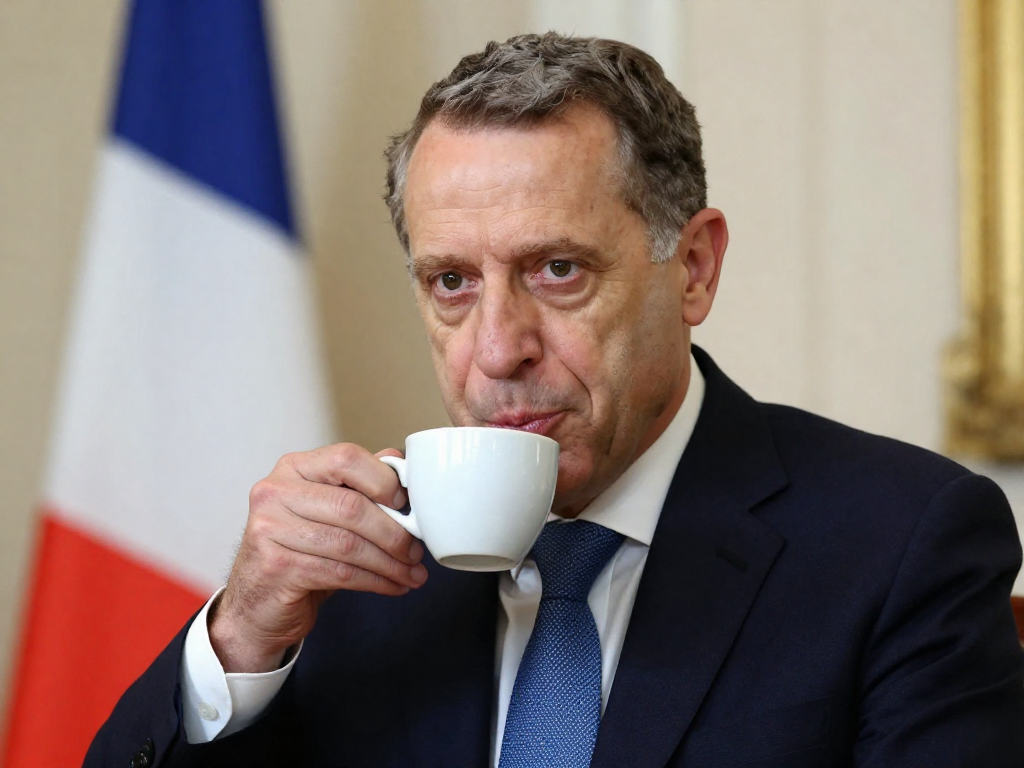

In [ ]:
from smolagents import tool
from pydantic import BaseModel

@tool
def generate_image(prompt: str) -> dict:
    """
    Generate an image from a prompt.

    Args:
      prompt: The prompt to generate the image from.

    Returns:
      The path to the generated image.
    """
    from huggingface_hub import InferenceClient
    import os

    image_client = InferenceClient(provider="fal-ai", api_key=os.getenv("HF_TOKEN"))
    pil_image = image_client.text_to_image(prompt, model="Tongyi-MAI/Z-Image-Turbo")
    return pil_image

generate_image("Generate an image of the current president of france drinking coffee")

In [ ]:
# run the agent with a couple of tools

from smolagents import ToolCallingAgent, WebSearchTool
import datetime

agent = ToolCallingAgent(
    tools=[WebSearchTool(), generate_image],
    model=model
)

# agent.run(f"""
# Current date: {datetime.datetime.now().strftime("%Y-%m-%d")}
# Generate an image of the current president of france drinking coffee.
# Return only the image.
# """)

## Use open source tools from the hub

In [ ]:
generate_image.push_to_hub(
    "alejandro-ao/z-image-turbo", token=os.getenv("HF_TOKEN")
    )

In [ ]:
# Load your tool from the hub

from smolagents import Tool

image_tool_from_hub = Tool.from_hub(
    repo_id="alejandro-ao/z-image-turbo",
    api_key=os.getenv("HF_TOKEN"),
    trust_remote_code=True,
)

agent = ToolCallingAgent(
    tools=[WebSearchTool(), image_tool_from_hub],
    model=model,
)

agent.run("generate a realistic image of a cat playing the guitar and wearing a sombrero. return only the image")

Loaded as API: https://black-forest-labs-flux-1-dev.hf.space ✔


/usr/local/lib/python3.12/dist-packages/smolagents/tools.py:666: UserWarning: Since `api_name` was not defined, it was automatically set to the first available API: `/infer`.
  warnings.warn(


╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ generate an image of a the current top artist on spotify playing the trumpet. return only the image             │
│                                                                                                                 │
╰─ InferenceClientModel - moonshotai/Kimi-K2-Instruct ────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'web_search' with arguments: {'query': 'current top artist on Spotify 2024'}                      │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: ## Search Results

|Revealed: The Top Artists, Songs, Albums, Podcasts, and ... - 
Spotify](https://newsroom.spotify.com/2024-12-04/top-songs-artists-podcasts-audiobooks-albums-trends-2024/)
Keep reading to discover the artists , songs, albums, and podcasts that topped our lists in 2024 , and find out how
they compare to your personalized Wrapped experience. The top global artist of 2024 With more than 26.6 billion 
streams globally, Taylor Swift is Spotify's  2024 Global Top  Artist .

|Spotify Top 100 Artists by Monthly Listeners | Spotify Stats](https://spotifystats.com/top-artists)
Discover the top 100 most popular artists  on  Spotify ranked by monthly listeners, updated regularly with current 
data.

|List of most-streamed artists on Spotify - 
Wikipedia](https://en.wikipedia.org/wiki/List_of_most-streamed_artists_on_Spotify)
As of December 2025, American singer-songwriter Taylor Swift is the most-streamed artist , |2] and Puerto Rican 
rapper Bad Bunny is the most-streamed male artist in Spotify's history. |3]|4]|a] Since 2013, Spotify has published
a yearly list of its most-streamed artists , which has been topped by Bad Bunny a record four times (2020-2022; 
2025 ...

|Spotify most streamed artists of 2024 - 
ChartMasters](https://chartmasters.org/spotify-most-streamed-artists-2024/)
In 2024 , Sheeran lost his position as the most-followed artist  on  Spotify , now ranking third. His spot among 
the platform's five most-streamed artists of all time is also under threat for 2025. This decline is particularly 
stark as the other four artists  on that list remain firmly in the top four of this year's tally, as we'll see 
later.

|Spotify Wrapped 2024: The 10 most-streamed artists 
revealed](https://mashable.com/article/spotify-wrapped-2024-most-streamed-artists)
For a second year, Taylor Swift is Spotify's most-streamed artist globally, but who else made the list? We've 
rounded up 2024's most-streamed artists , songs, and albums.

|Spotify Wrapped is out. Here's who topped the 2024 streaming charts - 
CNBC](https://www.cnbc.com/2024/12/04/spotify-wrapped-is-out-heres-who-topped-the-2024-streaming-charts.html)
 Spotify Wrapped 2024 is out, giving hundreds of millions of users the ability to see their most-played songs and 
artists over the course of the year.

|Spotify Wrapped 2024 stats revealed: Top artists, songs, 
albums](https://www.usatoday.com/story/entertainment/music/2024/12/04/spotify-wrapped-most-streamed-artists-2024/76
706061007/)
 Spotify Wrapped 2024 stats revealed: Top  artists , songs, albums Who are the top  artists  on  Spotify ? With the
release of Wrapped, now a pop-culture holiday in itself, we know the musicians and ...

|Spotify - Top Artists by Monthly Listeners - Kworb.net](https://www.kworb.net/spotify/listeners.html)
 Spotify  top  artists by monthly listeners Statistics since March 1st 2023.

|Top 10 Most-Streamed Artists, Songs and more on Spotify 
2024](https://ar-pay.com/blog/en/music-platforms/spotify/spotify-2024/)
Explore the ultimate list of 2024's  top 10 Most-Streamed artists , songs, and more on Spotify . Stay updated with 
the latest music trends and global favorites.

|Taylor Swift Reigns as Spotify 2024's Global Top 
Artist](https://thebeat.asia/vibe/pop-culture/spotify-wrapped-2024)
The year 2024 is truly her era, as American singer-songwriter Taylor Swift is named Spotify's Global Top  Artist 
for 2024 ! The pop superstar snags the top spot in the category with over 26.6 billion streams globally from 
January. The announcement came with the launch of Spotify 's " 2024 Wrapped," which offers a look into the most 
streamed artists , songs, albums, audiobooks, and ...

... (6 outputs left out)

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'final_answer' with arguments: {'answer': 'image.png'}                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: Stored 'image.png' in memory.

Final answer: /tmp/tmpymkbarcy/5881a96b-6b4d-4d20-93b1-c2d3ddb8b898.png

[Step 3: Duration 1.88 seconds| Input tokens: 6,335 | Output tokens: 94]

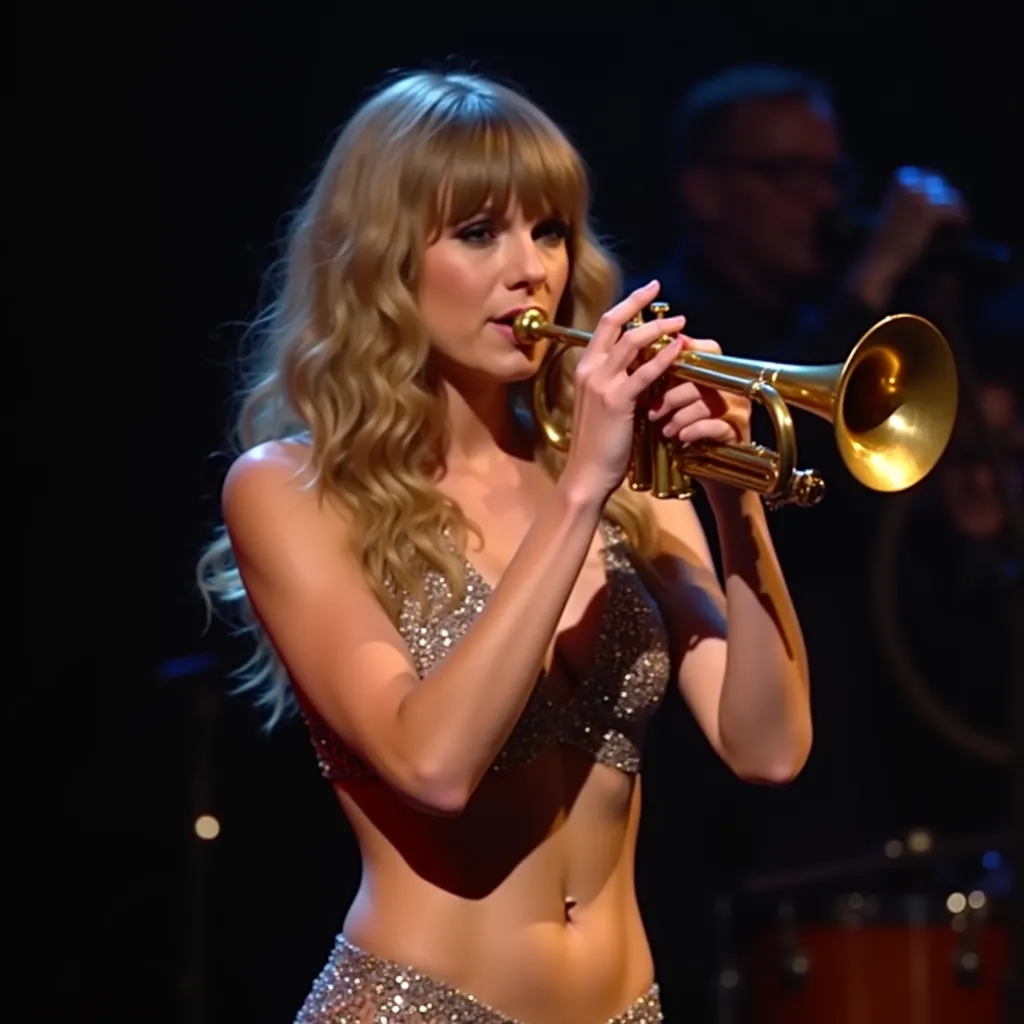

In [ ]:
# load a space as a tool

from smolagents import Tool, WebSearchTool

flux_tool = Tool.from_space(
    space_id="black-forest-labs/FLUX.1-dev",
    name="generate_image",
    description="Generate an image from a prompt"
)

agent = ToolCallingAgent(
    tools=[flux_tool, WebSearchTool()],
    model=model,
)

agent.run("generate an image of a the current top artist on spotify playing the trumpet. return only the image")

## GUI Chatbot

In [ ]:
from smolagents import GradioUI

gradio_ui = GradioUI(agent, reset_agent_memory=True)
gradio_ui.launch()

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://39c95b151e215860f8.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


╭──────────────────────────────────────────────────── New run ────────────────────────────────────────────────────╮
│                                                                                                                 │
│ Current date: December 2025                                                                                     │
│ Generate an image of the current PM of England                                                                  │
│ Return only the image.                                                                                          │
│                                                                                                                 │
╰─ InferenceClientModel - moonshotai/Kimi-K2-Instruct ────────────────────────────────────────────────────────────╯

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ Step 1 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'web_search' with arguments: {'query': 'current Prime Minister of England December 2025'}         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: ## Search Results

|List of prime ministers of the United Kingdom - Simple English 
...](https://simple.wikipedia.org/wiki/List_of_Prime_Ministers_of_the_United_Kingdom)
The Prime  Minister  of the United Kingdom is the leader of His Majesty's Government. They chair Cabinet meetings. 
It is the highest civil office in the United Kingdom. |source?] The present prime  minister has been Keir Starmer 
since 5 July 2024. |1]

|Prime Minister - GOV.UK](https://www.gov.uk/government/ministers/prime-minister)
PM meeting with Belgian Prime  Minister Bart de Wever: 12 December  2025 12 December  2025 Press release

|Keir Starmer confirmed as Britain's new prime minister after Labour 
...](https://www.nbcnews.com/news/world/live-blog/uk-general-election-live-results-britain-starmer-win-labour-rcna1
60339)
At the palace, King Charles formally appointed Starmer as the United Kingdom's new prime  minister following a 
landslide victory for the Labour party in yesterday's general election.

|Keir Starmer elected new UK prime minister after big Labour Party 
win](https://www.foxnews.com/world/keir-starmer-become-new-british-prime-minister-after-big-labour-party-win)
Keir Starmer officially became the new prime  minister  of the United Kingdom after the Labor Party's big win 
Thursday in the general election, The Associated Press reported.

|Keir Starmer sworn in as Prime Minister of the United 
Kingdom](https://utkarsh.com/current-affairs/international/appointments/keir-starmer-appointed-58th-prime-minister-
of-the-united-kingdom)
Sir Keir Starmer has been appointed as the new Prime  Minister  of the United Kingdom by Monarch King Charles III 
on 5 July 2024 at Buckingham Palace in London. Sir Keir Starmer is the 58th Prime  Minister  of the United Kingdom.
Buckingham Palace is the official residence and office of the United Kingdom monarch. Sir Keir Starmer's Labour 
Party won a landslide victory in the recently held ...

|Prime Minister of the United Kingdom | Current Leader](https://planetrulers.com/united-kingdom-prime-minister/)
Rishi Sunak (born 12 May 1980) is a British politician who has served as Prime  Minister  of the United Kingdom and
Leader of the Conservative Party since October 2022. He previously served as Chancellor of the Exchequer from 2020 
to 2022 and Chief Secretary to the Treasury from 2019 to 2020.

|5 Things To Know About Britain's New Prime Minister - 
HuffPost](https://www.huffpost.com/entry/5-things-to-know-about-keir-starmer_n_668403c3e4b038babc7d04a7)
5 Things To Know About Britain's New Prime  Minister Keir Starmer, the leader of the center-left Labour Party, will
succeed Rishi Sunak as U.K. leader.

|Who is Keir Starmer, the man on course to become new British Prime 
Minister](https://www.business-standard.com/world-news/who-is-keir-starmer-the-man-on-course-to-become-new-british-
prime-minister-124070500262_1.html)
Who is Keir Starmer? Keir Starmer, the leader of the UK Labour Party, previously served as a human rights lawyer 
and public prosecutor. If the exit polls hold true, Starmer, at the age of 61, will become the oldest individual to
assume the role of British Prime  Minister in nearly 50 years, having only entered Parliament nine years ago.

|UK Prime Minister List in Chronological order from 1721 to 2025 
PDF](https://sarkarilist.in/uk-prime-minister-list/)
UK Prime  Minister List from 1721 to 2025 Robert Walpole holds the distinction of being the first Prime  Minister  
of the UK and is also recognized as the longest-serving Prime  Minister . As of now, Boris Johnson is the current  
Prime  Minister  of Great Britain.

|Premiership of Keir Starmer - Wikipedia](https://en.wikipedia.org/wiki/Premiership_of_Keir_Starmer)
In September 2025 , his government formally recognised the State of Palestine. Despite winning a record amount of 
seats within Parliament, Starmer has suffered from low favourability among the British public during his tenure as 
Prime  Minister .

[Step 1: Duration 4.21 seconds| Input tokens: 1,179 | Output tokens: 39]

... (100 outputs left out)

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Calling tool: 'final_answer' with arguments: {'answer': 'image.png'}                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Observations: Stored 'image.png' in memory.

Final answer: /tmp/tmpxl52rfuf/ab01e511-09ce-4b42-9935-11b36b569670.png

[Step 3: Duration 1.88 seconds| Input tokens: 5,791 | Output tokens: 148]